Active compute environment: cuda

==================== Training ResNet-18 on MNIST ====================
Training on cuda for 10 epochs (SGD, lr=0.01, batch_size=32)...
Epoch [1/10], Loss: 0.1216
Epoch [2/10], Loss: 0.0299
Epoch [3/10], Loss: 0.0170
Epoch [4/10], Loss: 0.0100
Epoch [5/10], Loss: 0.0070
Epoch [6/10], Loss: 0.0038
Epoch [7/10], Loss: 0.0023
Epoch [8/10], Loss: 0.0016
Epoch [9/10], Loss: 0.0009
Epoch [10/10], Loss: 0.0007
Training finished in 273.56 seconds.
Metrics -> Acc: 0.9953 | Precision: 0.9953 | Recall: 0.9952 | F1: 0.9952


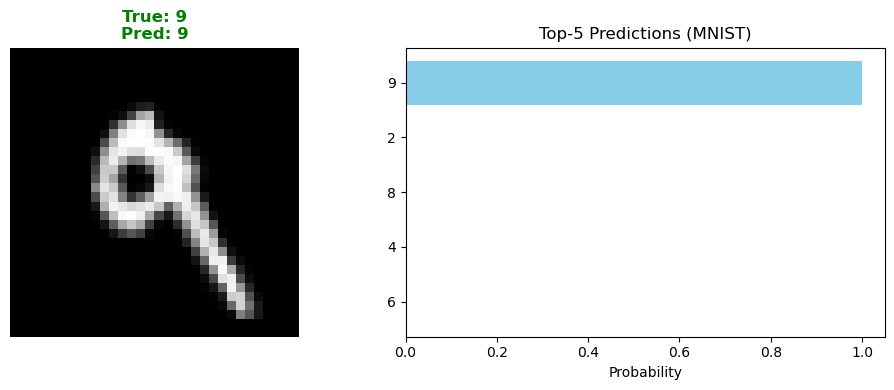


==================== Training ResNet-18 on CIFAR10 ====================
Training on cuda for 10 epochs (SGD, lr=0.01, batch_size=32)...
Epoch [1/10], Loss: 1.2885
Epoch [2/10], Loss: 0.7829
Epoch [3/10], Loss: 0.5481
Epoch [4/10], Loss: 0.3857
Epoch [5/10], Loss: 0.2510
Epoch [6/10], Loss: 0.1578
Epoch [7/10], Loss: 0.1043
Epoch [8/10], Loss: 0.0693
Epoch [9/10], Loss: 0.0583
Epoch [10/10], Loss: 0.0380
Training finished in 269.01 seconds.
Metrics -> Acc: 0.7884 | Precision: 0.7951 | Recall: 0.7884 | F1: 0.7824


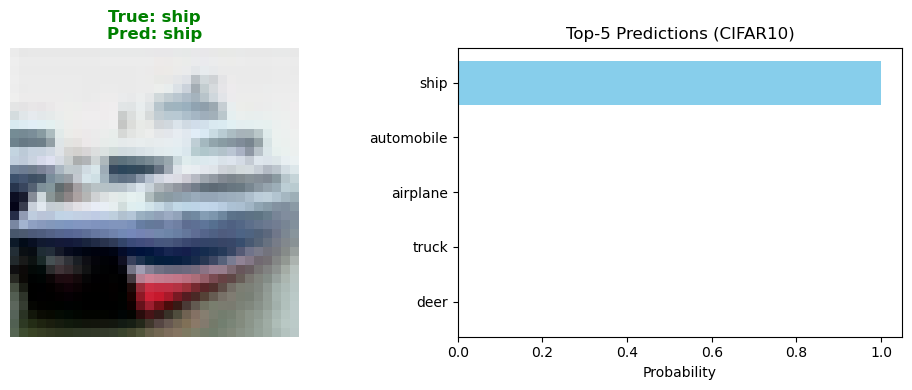


==================== Training ResNet-18 on CIFAR100 ====================
Training on cuda for 10 epochs (SGD, lr=0.01, batch_size=32)...
Epoch [1/10], Loss: 3.5465
Epoch [2/10], Loss: 2.6639
Epoch [3/10], Loss: 2.1424
Epoch [4/10], Loss: 1.7475
Epoch [5/10], Loss: 1.4157
Epoch [6/10], Loss: 1.1009
Epoch [7/10], Loss: 0.7787
Epoch [8/10], Loss: 0.4923
Epoch [9/10], Loss: 0.2539
Epoch [10/10], Loss: 0.1137
Training finished in 269.32 seconds.
Metrics -> Acc: 0.5188 | Precision: 0.5444 | Recall: 0.5188 | F1: 0.5214


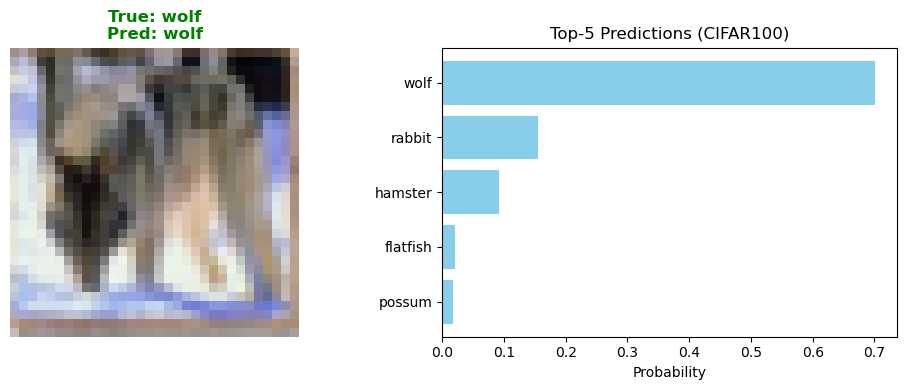


==================== Ablation on Residual Connections (CIFAR-10, 3 Epochs) ====================

--- 1. PlainNet-18 (Without Shortcut Connections) ---
Training on cuda for 3 epochs (SGD, lr=0.01, batch_size=32)...
Epoch [1/3], Loss: 1.3544
Epoch [2/3], Loss: 0.8150
Epoch [3/3], Loss: 0.5918
Training finished in 76.74 seconds.
Metrics -> Acc: 0.7738 | Precision: 0.7889 | Recall: 0.7738 | F1: 0.7713

--- 2. ResNet-18 (With Shortcut Connections) ---
Training on cuda for 3 epochs (SGD, lr=0.01, batch_size=32)...
Epoch [1/3], Loss: 1.2955
Epoch [2/3], Loss: 0.7987
Epoch [3/3], Loss: 0.5618
Training finished in 80.38 seconds.
Metrics -> Acc: 0.7197 | Precision: 0.7523 | Recall: 0.7197 | F1: 0.7120


In [2]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, Dict

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ---------------------------------------------------------
# 1. Reproducibility and Hardware Acceleration Setup
# ---------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active compute environment: {device}")

# ---------------------------------------------------------
# 2. General Data Loading Pipeline
# ---------------------------------------------------------
def get_dataloaders(dataset_name: str, batch_size: int = 32):
    dataset_name = dataset_name.upper()
    if dataset_name == "MNIST":
        transform = transforms.Compose([
            transforms.Resize((32, 32)),
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])
        train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
        in_channels, num_classes, classes = 1, 10, tuple(str(i) for i in range(10))
        
    elif dataset_name == "CIFAR10":
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
        ])
        train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
        in_channels, num_classes, classes = 3, 10, train_set.classes
        
    elif dataset_name == "CIFAR100":
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
        ])
        train_set = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
        in_channels, num_classes, classes = 3, 100, train_set.classes
    else:
        raise ValueError(f"Unknown dataset: {dataset_name}")

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=2)
    return train_loader, test_loader, in_channels, num_classes, classes

# ---------------------------------------------------------
# 3. Training and Evaluation Function
# ---------------------------------------------------------
def train_and_evaluate(
    model: nn.Module,
    train_loader: DataLoader,
    test_loader: DataLoader,
    epochs: int = 10,
    lr: float = 0.01
) -> Dict:
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    train_loss_history = []
    
    print(f"Training on {device} for {epochs} epochs (SGD, lr={lr}, batch_size=32)...")
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        train_loss_history.append(epoch_loss)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")
        
    total_training_time = time.time() - start_time
    print(f"Training finished in {total_training_time:.2f} seconds.")
    
    # Comprehensive evaluation
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(labels.numpy())
            
    accuracy = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average='macro', zero_division=0
    )
    
    metrics = {
        "training_time": total_training_time,
        "train_loss_history": train_loss_history,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }
    print(f"Metrics -> Acc: {accuracy:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
    return metrics

# ---------------------------------------------------------
# 4. ResNet-18 Implementation Built from Scratch
# ---------------------------------------------------------
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes: int, planes: int, stride: int = 1):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(self.expansion * planes)
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)  # Identity shortcut connection: F(x) + x
        out = F.relu(out)
        return out

class ResNet18FromScratch(nn.Module):
    def __init__(self, in_channels: int = 3, num_classes: int = 10):
        super(ResNet18FromScratch, self).__init__()
        self.in_planes = 64

        # Tailored for 32x32 image resolutions
        self.conv1 = nn.Conv2d(in_channels, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        
        # 4 residual stages (each stage contains 2 basic blocks)
        self.layer1 = self._make_layer(BasicBlock, 64, num_blocks=2, stride=1)
        self.layer2 = self._make_layer(BasicBlock, 128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(BasicBlock, 256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(BasicBlock, 512, num_blocks=2, stride=2)
        
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.linear = nn.Linear(512 * BasicBlock.expansion, num_classes)

    def _make_layer(self, block, planes: int, num_blocks: int, stride: int) -> nn.Sequential:
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(block(self.in_planes, planes, s))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        out = self.linear(out)
        return out

    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.forward(x)
        return F.softmax(logits, dim=-1)

# ---------------------------------------------------------
# 5. Prediction Visualization
# ---------------------------------------------------------
def visualize_single_prediction(model, test_loader, classes, dataset_name):
    model.eval()
    dataiter = iter(test_loader)
    images, labels = next(dataiter)
    idx = random.randint(0, images.size(0) - 1)
    
    img_tensor = images[idx].unsqueeze(0).to(device)
    true_label = classes[labels[idx].item()]
    
    with torch.no_grad():
        probs = model.predict_proba(img_tensor).cpu().squeeze().numpy()
        
    top5_idx = probs.argsort()[-5:][::-1]
    top5_probs = probs[top5_idx]
    top5_labels = [classes[i] for i in top5_idx]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    img_disp = images[idx].cpu()
    
    if img_disp.shape[0] == 1:
        ax1.imshow(img_disp.squeeze(), cmap='gray')
    else:
        img_disp = img_disp.permute(1, 2, 0).numpy()
        img_disp = (img_disp * np.array([0.2470, 0.2435, 0.2616]) + np.array([0.4914, 0.4822, 0.4465])).clip(0, 1)
        ax1.imshow(img_disp)
        
    color = "green" if top5_labels[0] == true_label else "red"
    ax1.set_title(f"True: {true_label}\nPred: {top5_labels[0]}", color=color, fontweight='bold')
    ax1.axis('off')
    
    ax2.barh(range(5), top5_probs, align='center', color='skyblue')
    ax2.set_yticks(range(5))
    ax2.set_yticklabels(top5_labels)
    ax2.invert_yaxis()
    ax2.set_xlabel('Probability')
    ax2.set_title(f"Top-5 Predictions ({dataset_name})")
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 6. Main Execution Pipeline Across 3 Datasets
# ---------------------------------------------------------
resnet_experiments = {}

for d_name in ["MNIST", "CIFAR10", "CIFAR100"]:
    print(f"\n==================== Training ResNet-18 on {d_name} ====================")
    train_loader, test_loader, in_channels, num_classes, classes = get_dataloaders(d_name, batch_size=32)
    
    model = ResNet18FromScratch(in_channels=in_channels, num_classes=num_classes).to(device)
    results = train_and_evaluate(model, train_loader, test_loader, epochs=10, lr=0.01)
    resnet_experiments[d_name] = results
    
    visualize_single_prediction(model, test_loader, classes, d_name)

# ---------------------------------------------------------
# 7. Ablation: Deep Plain Network vs ResNet-18 (Addressing Training Degradation)
# ---------------------------------------------------------
class PlainBlock(nn.Module):
    expansion = 1
    def __init__(self, in_planes, planes, stride=1):
        super(PlainBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        # Plain setup: no residual shortcut addition
        out = F.relu(out)
        return out

class PlainNet18(ResNet18FromScratch):
    def __init__(self, in_channels=3, num_classes=10):
        super(PlainNet18, self).__init__(in_channels=in_channels, num_classes=num_classes)
        self.in_planes = 64
        self.layer1 = self._make_layer(PlainBlock, 64, 2, stride=1)
        self.layer2 = self._make_layer(PlainBlock, 128, 2, stride=2)
        self.layer3 = self._make_layer(PlainBlock, 256, 2, stride=2)
        self.layer4 = self._make_layer(PlainBlock, 512, 2, stride=2)

print("\n==================== Ablation on Residual Connections (CIFAR-10, 3 Epochs) ====================")
train_loader, test_loader, in_channels, num_classes, classes = get_dataloaders("CIFAR10", batch_size=32)

print("\n--- 1. PlainNet-18 (Without Shortcut Connections) ---")
plain_model = PlainNet18(in_channels=3, num_classes=10).to(device)
plain_results = train_and_evaluate(plain_model, train_loader, test_loader, epochs=3, lr=0.01)

print("\n--- 2. ResNet-18 (With Shortcut Connections) ---")
res_model = ResNet18FromScratch(in_channels=3, num_classes=10).to(device)
res_results = train_and_evaluate(res_model, train_loader, test_loader, epochs=3, lr=0.01)